In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings
 
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
 
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('gazebo_full+_dataset_synced.csv')


In [3]:
df

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,76.109,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...,...,...,...,...
95865,1354.681,-0.154206,-0.471443,0.801403,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,1354.681,-0.154157,-0.471496,0.801452,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,1354.681,-0.154109,-0.471548,0.801501,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,1354.681,-0.154060,-0.471601,0.801549,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [4]:
df.describe()

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
count,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000,95870.000000
mean,1510.495158,0.049861,0.022569,0.762274,-0.125948,0.046854,-0.352591,0.800791,-0.258203,-1.375961,-0.190765
std,2219.154855,0.333866,0.352429,0.361617,1.646092,0.954804,2.025295,3.572670,1.530393,7.763283,1.752245
min,76.109000,-0.794150,-0.840471,-0.716202,-2.773854,-2.028950,-8.088039,-2.104892,-2.940508,-43.638002,-16.426336
25%,201.154000,-0.154784,-0.232761,0.478756,-1.540355,-0.570780,-1.313833,-0.620000,-1.628157,-0.828176,-1.351246
50%,315.650000,0.023001,-0.000005,0.789397,0.000013,0.000067,-0.000066,0.049822,-0.000070,-0.000016,-0.000057
75%,1265.010000,0.277337,0.290886,1.075479,1.090419,0.788004,0.909329,1.135364,0.714148,0.831085,0.816528
max,6658.649000,1.000957,0.831571,1.220999,2.867152,1.904753,2.846485,19.466906,2.922250,2.400718,2.957545


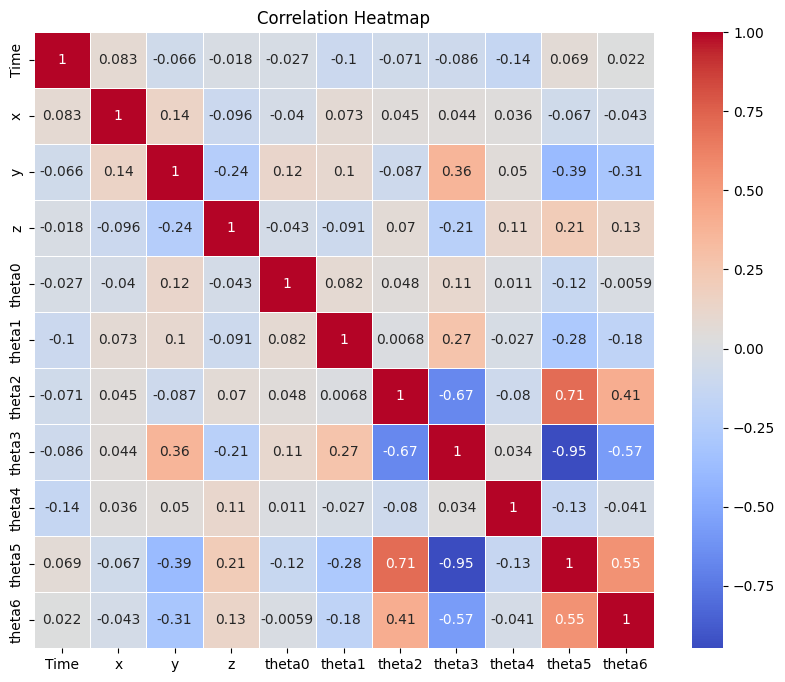

In [5]:
#df = df.iloc[:20000,:]
#Plotting correlation heatmap
correlation_matrix =df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5) 
plt.title("Correlation Heatmap")
plt.show()

In [6]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [7]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [8]:
X.shape

(95870, 3)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
 
#Check for and handle categorical variables
label_encoder = LabelEncoder()
x_categorical = df.select_dtypes(include=['object']).apply(label_encoder.fit_transform)
x_numerical = df.select_dtypes(exclude=['object']).values
x = pd.concat([pd.DataFrame(x_numerical), x_categorical], axis=1).values
 
# Fitting Random Forest Regression to the dataset
rregressor = RandomForestRegressor(n_estimators=20, random_state=0, oob_score=True)
 
# Fit the regressor with x and y data
rregressor.fit(X, y)

RandomForestRegressor(n_estimators=20, oob_score=True, random_state=0)

In [22]:
# Evaluating the model
from sklearn.metrics import mean_squared_error, r2_score
 
# Access the OOB Score
oob_score = rregressor.oob_score_
print(f'Out-of-Bag Score: {oob_score}')
 
# Making predictions on the same data or new data
predictions = rregressor.predict(X)
 
# Evaluating the model
mse = mean_squared_error(y, predictions)
print(f'Mean Squared Error: {mse}')
 
r2 = r2_score(y, predictions)
print(f'R-squared: {r2}')

Out-of-Bag Score: 0.9945393378010403
Mean Squared Error: 0.0049385221479206825
R-squared: 0.9991744333946426


In [23]:
print(rregressor.predict([[0.3, 0.4, 0.5]]))

[[ 0.42662418  0.10870512  1.49297003  1.39813741 -0.91857375 -1.03640891
   0.76256096]]
